# Stage 1: "Is there a problem?" classifier (Brandon)

**What this notebook does, in plain words:** it teaches a pretrained image model (EfficientNet-B0) to answer one
question about a mouth photo: *does it show any of the five conditions, or does it look healthy?*
This is stage 1 of the two-stage plan. Stage 2 (YOLO) then finds **where** the problem is and **what** it is.

**Data:** Daniel's merged dataset (`oral_dataset`, built 2026-11-11 by `qwen_clean_and_label.ipynb`). Target = `has_issue`
in `labels.csv` (1 = at least one of Calculus / Caries / Hypodontia / Mouth ulcer / Tooth discolouration, 0 = healthy).
Val and test are shared with the YOLO stage, so the whole pipeline can be scored on the same photos.

**What we report** (on the test set, twice: all test photos, and only photos labelled entirely by people):
- **Recall on "issue"**: of the photos that really have a problem, how many we flag. This is the number that matters
  most; a missed problem is the dangerous mistake.
- **Recall on "healthy"**: of the healthy photos, how many we correctly leave alone.
- Balanced accuracy, ROC-AUC, confusion matrix, per-source and per-condition breakdowns, and robustness to bad photos.

**Watch out: a shortcut in the shared val/test sets.** In them, *every* photo with a condition comes from Roboflow and
*every* healthy photo comes from another source. A model could score highly just by recognising "a Roboflow-style
photo" without looking at the teeth. So this notebook adds a third test, **`test_mixed`**: photos held out of training
from the four sources that have both healthy and problem photos (Zenodo, DentalAI, Kaggle, web images). There the
source gives nothing away, so **`test_mixed` is the honest score**. A big gap between `test_all` and `test_mixed`
means the model leans on the shortcut.

**Run it:** pick the `.venv-train` kernel and Run All. Set the environment variable `ISSUE_SMOKE=1` for a 2-minute check
on a few hundred photos before the real run.

## 0. Setup

In [1]:
import json, os, random, re, time, copy
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision as tv
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_auc_score
from torchvision.transforms import v2
from tqdm.auto import tqdm

from issue_data import CORRUPTIONS, OralDS, make_cache

print("torch", torch.__version__, "| torchvision", tv.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU will be very slow)")

D:\nyp\Sem 2\AI Innovation Deep learning\.venv-train\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.7.1+cu126 | torchvision 0.22.1+cu126


GPU: NVIDIA GeForce GTX 1050 Ti with Max-Q Design


## 1. Settings  ← the only cell you normally edit

`CACHE_SIDE`: photos are shrunk once to at most this many pixels on the long side and saved next to the dataset.
The originals go up to 6720 px, and decoding those every epoch would make training many times slower.

In [2]:
NB_DIR = Path.cwd()
REPO = next(p for p in [NB_DIR, *NB_DIR.parents] if (p / "shared" / "conditions.yaml").exists())
DATA_DIR = Path(os.environ.get("ORAL_DATA", REPO.parent / "datasets" / "oral_dataset_new" / "oral_dataset"))
CACHE_SIDE = 288
CACHE_DIR = DATA_DIR.parent / f"cache_{CACHE_SIDE}"

SMOKE = os.environ.get("ISSUE_SMOKE") == "1"   # quick end-to-end check on a small sample
EXPERIMENT = "B1_effb0_issue" + ("_smoke" if SMOKE else "")

IMG_SIZE = 224
BATCH = 32            # fits a 4 GB GPU with mixed precision
HEAD_EPOCHS = 1       # phase 1: train only the new last layer
EPOCHS = 2 if SMOKE else 12   # total epochs including phase 1
LR_HEAD, LR = 1e-3, 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 3          # stop if val AUC hasn't improved for this many epochs
TARGET_RECALL = 0.95  # pick the decision threshold so val recall on "issue" is at least this
UNSURE_BELOW = 0.65   # calibrated confidence under this -> "not sure, see a dentist"
NUM_WORKERS = 4
MIXED_SOURCES = ["zenodo", "dentalai", "kaggle_oral", "external_clean"]   # sources with both classes
MIXED_FRAC = 0.15     # share of their training photos held out as the fair test (test_mixed)
SEED = 42

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet, as the backbone was trained
CONDITIONS = ["Calculus", "Caries", "Hypodontia", "Mouth_Ulcer", "Tooth_Discoloration"]

OUT_DIR = REPO / "models" / "classifier" / "results" / "Brandon"
WEIGHTS_DIR = REPO / "models" / "classifier" / "weights" / "Brandon"
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, WEIGHTS_DIR, FIG_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("data:", DATA_DIR, "| smoke run:", SMOKE, "| device:", device)

data: D:\nyp\Sem 2\AI Innovation Deep learning\datasets\oral_dataset_new\oral_dataset | smoke run: False | device: cuda


## 2. Load the labels and look at the split

Each row of `labels.csv` is one photo. `label_by` says who decided its labels: `person`, `qwen`, or a mix.

In [3]:
df = pd.read_csv(DATA_DIR / "labels.csv")
df["src"] = [str(DATA_DIR / p) for p in df["image"]]
df["cache"] = [str(CACHE_DIR / (Path(p).stem + ".jpg")) for p in df["image"]]
df["person_only"] = df["label_by"].eq("person")

# --- fair test set (test_mixed): hold out whole patients / copy groups from the mixed sources ---
def patient_id(src):   # Zenodo file names carry the patient, e.g. anonymous_003-007-1214-00_...
    m = re.search(r"anonymous_(\d+)[-_](\d+)[-_](\d+)", str(src))
    return "p" + "-".join(m.groups()) if m else None

df["patient"] = [patient_id(s) for s in df["source_file"]]
# Daniel's split keeps copies of a photo together but not other photos of the same Zenodo patient:
# drop training photos of patients who also appear in val/test, so the model never saw that mouth.
eval_patients = set(df.loc[df["split"].isin(["val", "test"]), "patient"].dropna())
leak = df["split"].eq("train") & df["patient"].isin(eval_patients)
df.loc[leak, "split"] = "unused"
print(f"{int(leak.sum())} training photos dropped: same patient as a val/test photo")
in_train = df["split"].eq("train")
unit = df["patient"].fillna("g" + df["group"].astype(str))     # one patient, or one copy group
cand = unit[in_train & df["dataset"].isin(MIXED_SOURCES)]
sizes = cand.value_counts()
order = sizes.index.to_numpy().copy(); np.random.default_rng(SEED).shuffle(order)
held_units, n = set(), 0
for u in order:
    if n >= MIXED_FRAC * len(cand):
        break
    if sizes[u] <= 50:   # leave the few giant copy groups in train
        held_units.add(u); n += sizes[u]
held = in_train & unit.isin(held_units)
while True:   # pull in every copy and every other photo of the same patient
    grow = in_train & (df["group"].isin(df.loc[held, "group"]) | df["patient"].isin(df.loc[held, "patient"].dropna()))
    if grow.sum() == held.sum():
        break
    held = grow
df.loc[held, "split"] = np.where(df.loc[held, "dataset"].isin(MIXED_SOURCES), "test_mixed", "unused")
df = df[df["split"] != "unused"].reset_index(drop=True)

if SMOKE:   # 150 photos per (split, class) is enough to check every cell runs
    idx = []
    for _, g in df.groupby(["split", "has_issue"]):
        idx += list(g.sample(min(len(g), 150), random_state=SEED).index)
    df = df.loc[idx].reset_index(drop=True)

print(len(df), "photos")
display(pd.crosstab(df["split"], df["has_issue"].map({0: "healthy", 1: "issue"}), margins=True))
display(pd.crosstab(df["split"], df["label_by"]))
print("fair test set (test_mixed) by source:")
display(pd.crosstab(df.loc[df.split == "test_mixed", "dataset"], df.loc[df.split == "test_mixed", "has_issue"].map({0: "healthy", 1: "issue"})))

1753 training photos dropped: same patient as a val/test photo
36142 photos


has_issue,healthy,issue,All
split,,,
test,963,2447,3410
test_mixed,888,1175,2063
train,5578,21867,27445
val,923,2301,3224
All,8352,27790,36142


label_by,person,person (caries) + qwen (other conditions),person (condition) + qwen (boxes),qwen
split,,,,
test,2506,418,0,486
test_mixed,23,1858,109,73
train,18627,4194,616,4008
val,2360,411,0,453


fair test set (test_mixed) by source:


has_issue,healthy,issue
dataset,,
dentalai,128,242
external_clean,13,57
kaggle_oral,23,112
zenodo,724,764


### Leakage check

A test set only means something if the model has never seen those photos in any form. Daniel's build keeps every copy
of a photo (`group`) inside one split, and the cell above keeps every Zenodo patient inside one split too.
This cell double-checks that no group, patient or identical file (`md5`) is in both train and an evaluation set.

In [4]:
for col in ("group", "patient", "md5"):
    seen_in_train = set(df.loc[df.split == "train", col].dropna())
    in_eval = set(df.loc[df.split != "train", col].dropna())
    print(f"{col}: {len(seen_in_train & in_eval)} shared between train and val/test/test_mixed (should be 0)")

group: 0 shared between train and val/test/test_mixed (should be 0)
patient: 0 shared between train and val/test/test_mixed (should be 0)
md5: 0 shared between train and val/test/test_mixed (should be 0)


### A few photos from each class

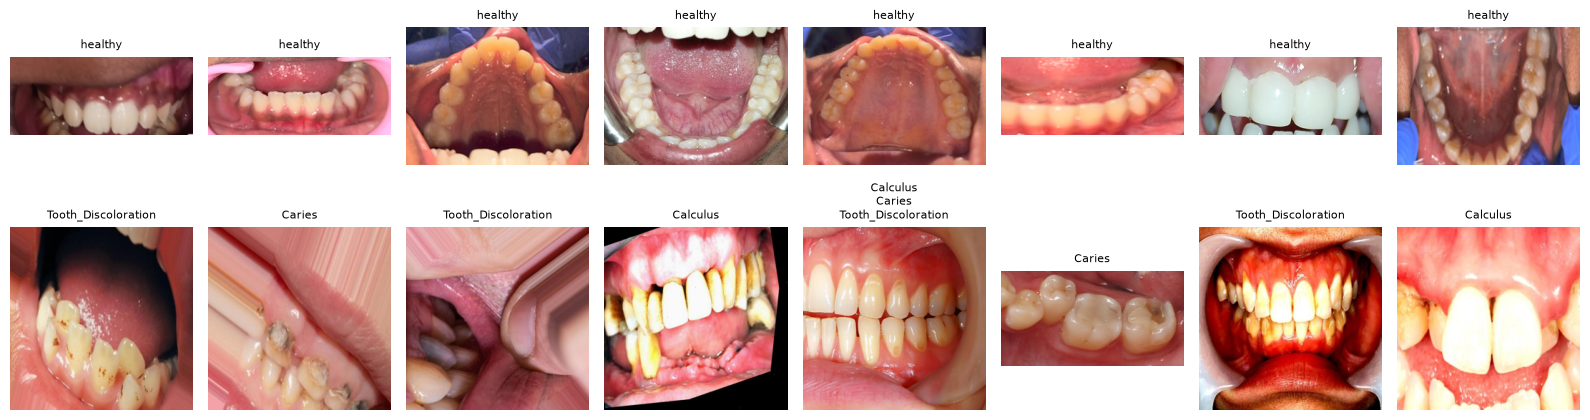

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for r, (lab, name) in enumerate([(0, "healthy"), (1, "issue")]):
    rows = df[(df.split == "train") & (df.has_issue == lab)].sample(8, random_state=SEED)
    for ax, (_, row) in zip(axes[r], rows.iterrows()):
        with Image.open(row.src) as im:
            im.thumbnail((256, 256)); ax.imshow(im.convert("RGB"))
        ax.set_title(name if lab == 0 else row["labels"].replace("|", "\n"), fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Shrink the photos once (cache)

Runs in parallel and skips files already cached, so a second run takes seconds. Unreadable photos are dropped and counted.

In [6]:
t0 = time.time()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as ex:
    ok = list(tqdm(ex.map(lambda a: make_cache(a[0], a[1], CACHE_SIDE), zip(df.src, df.cache)),
                   total=len(df), desc="caching"))
df = df[np.array(ok)].reset_index(drop=True)
print(f"{len(ok) - sum(ok)} unreadable photos dropped; {len(df)} kept; {time.time() - t0:.0f}s")

train_df, val_df, test_df, mixed_df = (df[df.split == s].reset_index(drop=True)
                                       for s in ("train", "val", "test", "test_mixed"))

caching:   0%|          | 0/36142 [00:00<?, ?it/s]

caching:   0%|          | 26/36142 [00:00<02:40, 225.44it/s]

caching:   0%|          | 49/36142 [00:00<03:13, 186.22it/s]

caching:   0%|          | 82/36142 [00:00<03:20, 180.29it/s]

caching:   0%|          | 116/36142 [00:00<02:40, 223.84it/s]

caching:   0%|          | 152/36142 [00:00<02:21, 253.93it/s]

... (859 outputs left out)

caching: 100%|█████████▉| 36003/36142 [02:03<00:00, 368.09it/s]

caching: 100%|█████████▉| 36047/36142 [02:04<00:00, 239.37it/s]

caching: 100%|██████████| 36142/36142 [02:04<00:00, 290.95it/s]

0 unreadable photos dropped; 36142 kept; 125s


## 4. Feed the photos to the model

**Training photos** get random small changes (crop, flip, rotation, colour) so the model sees more variety and can't
memorise exact pixels. The crop keeps at least 80% of the photo so a small lesion isn't cut out.
**Val/test photos** are only resized.

In [7]:
train_tf = v2.Compose([
    v2.ToImage(),
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), ratio=(0.8, 1.25), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.RandomRotation(15),
    v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])


def loader(frame, tf, shuffle=False, corrupt=None):
    ds = OralDS(frame.cache, frame.has_issue.astype(int), tf, corrupt)
    return torch.utils.data.DataLoader(ds, batch_size=BATCH, shuffle=shuffle, num_workers=NUM_WORKERS,
                                       pin_memory=device.type == "cuda", persistent_workers=NUM_WORKERS > 0)


train_dl, val_dl, test_dl = loader(train_df, train_tf, shuffle=True), loader(val_df, eval_tf), loader(test_df, eval_tf)
mixed_dl = loader(mixed_df, eval_tf)

## 5. Handle the imbalance

There are about 3 "issue" photos for every healthy one. A lazy model could say "issue" every time and look 75% right.
**Class weights** make a mistake on the rarer class cost more.

In [8]:
counts = train_df.has_issue.value_counts().sort_index()
class_w = torch.tensor((len(train_df) / (2 * counts)).values, dtype=torch.float32)
print("train counts (healthy, issue):", counts.tolist(), "| class weights:", [round(float(w), 2) for w in class_w])

train counts (healthy, issue): [5578, 21867] | class weights: [2.46, 0.63]


## 6. Build the model

A **pre-trained eye** (EfficientNet-B0, trained on ImageNet's 1.3 M everyday photos) plus a **new 2-way last layer**
(healthy / issue). EfficientNet-B0 is small (4 M parameters) and was among the best in Daniel's 12-backbone comparison.

In [9]:
def build_model():
    m = tv.models.efficientnet_b0(weights=tv.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    return m


model = build_model().to(device)
criterion = nn.CrossEntropyLoss(weight=class_w.to(device))
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

4.0 M parameters


## 7. Train

- **Phase 1** (`HEAD_EPOCHS`): the pre-trained eye is frozen and only the new layer learns.
- **Phase 2**: everything is unlocked and fine-tuned with a smaller learning rate that slowly decreases (cosine schedule).
- After every epoch we score the validation set. The best epoch (highest val ROC-AUC) is kept, and training stops early
  if it hasn't improved for `PATIENCE` epochs.

Mixed precision (`autocast`) halves the memory use so a batch of 32 fits on a 4 GB GPU.

In [10]:
@torch.no_grad()
def predict_logits(model, dl):
    model.eval()
    out, ys = [], []
    for x, y in dl:
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            out.append(model(x.to(device, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()


def p_issue(logits, T=1.0):
    return (logits / T).softmax(1)[:, 1].numpy()


def set_phase(head_only):
    for p in model.features.parameters():
        p.requires_grad = not head_only
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.AdamW(params, lr=LR_HEAD if head_only else LR, weight_decay=WEIGHT_DECAY)


scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
history, best_auc, best_state, bad_epochs = [], -1.0, None, 0
opt = set_phase(head_only=True)
sched = None

for epoch in range(1, EPOCHS + 1):
    if epoch == HEAD_EPOCHS + 1:
        opt = set_phase(head_only=False)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, (EPOCHS - HEAD_EPOCHS) * len(train_dl)))
    model.train()
    t0, total, n = time.time(), 0.0, 0
    for x, y in tqdm(train_dl, desc=f"epoch {epoch}/{EPOCHS}", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            loss = criterion(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        if sched is not None:
            sched.step()
        total += loss.item() * len(y); n += len(y)

    logits, yv = predict_logits(model, val_dl)
    pv = p_issue(logits)
    val_loss = nn.functional.cross_entropy(logits, torch.as_tensor(yv), weight=class_w).item()
    auc = roc_auc_score(yv, pv)
    rec_issue = ((pv >= 0.5) & (yv == 1)).sum() / max(1, (yv == 1).sum())
    rec_healthy = ((pv < 0.5) & (yv == 0)).sum() / max(1, (yv == 0).sum())
    history.append(dict(epoch=epoch, train_loss=total / n, val_loss=val_loss, val_auc=auc,
                        val_recall_issue=rec_issue, val_recall_healthy=rec_healthy, minutes=(time.time() - t0) / 60))
    print(f"epoch {epoch}: train loss {total / n:.3f} | val loss {val_loss:.3f} | val AUC {auc:.4f} | "
          f"recall issue {rec_issue:.3f} healthy {rec_healthy:.3f} | {(time.time() - t0) / 60:.1f} min")

    if auc > best_auc:
        best_auc, best_epoch, bad_epochs = auc, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE and epoch > HEAD_EPOCHS:
            print(f"stopping early: no val AUC gain for {PATIENCE} epochs")
            break

model.load_state_dict(best_state)
hist = pd.DataFrame(history)
print(f"best epoch {best_epoch}, val AUC {best_auc:.4f}")

epoch 1/12:   0%|          | 0/858 [00:00<?, ?it/s]

epoch 1/12:   0%|          | 1/858 [00:20<4:46:59, 20.09s/it]

epoch 1/12:   0%|          | 2/858 [00:20<1:58:53,  8.33s/it]

epoch 1/12:   0%|          | 4/858 [00:20<45:07,  3.17s/it]  

epoch 1/12:   1%|          | 6/858 [00:20<24:21,  1.72s/it]

epoch 1/12:   1%|          | 8/858 [00:20<15:01,  1.06s/it]

... (10,296 outputs left out)

epoch 12/12: 100%|█████████▉| 856/858 [14:48<00:02,  1.09s/it]

epoch 12/12: 100%|█████████▉| 857/858 [14:49<00:01,  1.08s/it]

epoch 12/12: 100%|██████████| 858/858 [14:50<00:00,  1.02it/s]

epoch 12: train loss 0.026 | val loss 0.277 | val AUC 0.9992 | recall issue 1.000 healthy 0.854 | 15.3 min
best epoch 10, val AUC 0.9993


### Did it learn? (training curves)

Train and val loss should both go down. If train keeps falling while val climbs, the model is memorising (overfitting);
early stopping keeps the epoch before that happens.

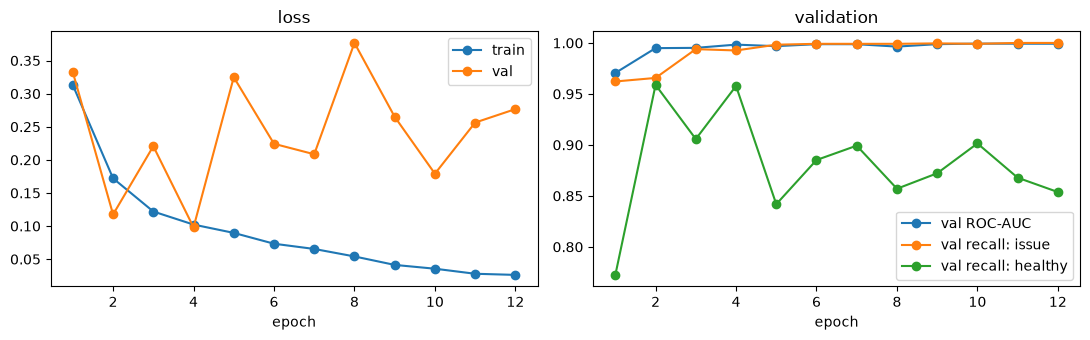

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.epoch, hist.train_loss, "o-", label="train"); ax[0].plot(hist.epoch, hist.val_loss, "o-", label="val")
ax[0].set_title("loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist.epoch, hist.val_auc, "o-", label="val ROC-AUC")
ax[1].plot(hist.epoch, hist.val_recall_issue, "o-", label="val recall: issue")
ax[1].plot(hist.epoch, hist.val_recall_healthy, "o-", label="val recall: healthy")
ax[1].set_title("validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / f"{EXPERIMENT}_curves.png", dpi=120); plt.show()

## 8. Calibrate, then choose the decision threshold (on validation only)

- **Temperature scaling**: raw model confidences tend to be over-confident. One number `T` is fitted on the validation
  set so that "80% sure" really means right about 80% of the time. This is what lets the app show honest probabilities.
- **Threshold**: by default a photo is "issue" when its probability is ≥ 0.5. For a screening tool, missing a problem is
  worse than a false alarm (a dentist visit), so the threshold is lowered until validation recall on "issue" reaches
  `TARGET_RECALL`.
- **Not sure**: when the calibrated confidence is below `UNSURE_BELOW`, the app should say "not sure, see a dentist"
  instead of giving an answer.

The test set is not touched in this step, so the test score stays an honest exam.

In [12]:
val_logits, yv = predict_logits(model, val_dl)

log_T = torch.zeros(1, requires_grad=True)
opt_T = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)
def closure():
    opt_T.zero_grad()
    loss = nn.functional.cross_entropy(val_logits / log_T.exp(), torch.as_tensor(yv))
    loss.backward()
    return loss
opt_T.step(closure)
T = float(log_T.exp())

pv = p_issue(val_logits, T)
threshold = float(np.quantile(pv[yv == 1], 1 - TARGET_RECALL))
threshold = min(threshold, 0.5)   # never make the model *less* sensitive than the default
print(f"temperature T = {T:.3f} | decision threshold = {threshold:.3f}")

temperature T = 1.676 | decision threshold = 0.500


## 9. Final exam: the test set

Three scores:
- **all test photos** (the shared test set, as the dataset README asks)
- **person-labelled test photos only** (no Qwen labels). If this is close to the first, Qwen's labels are fine.
  Note it holds very few healthy photos, so its "recall: healthy" is noisy.
- **test_mixed**: the fair test where the photo's source doesn't reveal the answer. **Quote this one first.**

In [13]:
def scores(y, p, t, conf_floor=UNSURE_BELOW):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    div = lambda a, b: a / b if b else float("nan")
    conf = np.maximum(p, 1 - p)
    sure = conf >= conf_floor
    return dict(
        n=len(y), n_issue=int((y == 1).sum()), n_healthy=int((y == 0).sum()),
        accuracy=div(tp + tn, len(y)),
        balanced_accuracy=np.nanmean([div(tp, tp + fn), div(tn, tn + fp)]),
        recall_issue=div(tp, tp + fn), recall_healthy=div(tn, tn + fp),
        precision_issue=div(tp, tp + fp),
        f1_issue=div(2 * tp, 2 * tp + fp + fn),
        roc_auc=roc_auc_score(y, p) if len(set(y)) > 1 else float("nan"),
        unsure_rate=float(1 - sure.mean()),
        accuracy_when_sure=div(int(((pred == y) & sure).sum()), int(sure.sum())),
        tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
    )


test_logits, yt = predict_logits(model, test_dl)
pt = p_issue(test_logits, T)
test_df["p_issue"] = pt
test_df["pred"] = (pt >= threshold).astype(int)
mixed_logits, ym = predict_logits(model, mixed_dl)
pm = p_issue(mixed_logits, T)
mixed_df["p_issue"] = pm
mixed_df["pred"] = (pm >= threshold).astype(int)

person = test_df.person_only.values
results = {
    "val": scores(yv, pv, threshold),
    "test_all": scores(yt, pt, threshold),
    "test_person_only": scores(yt[person], pt[person], threshold),
    "test_mixed": scores(ym, pm, threshold),
    "test_all_at_0.5": scores(yt, pt, 0.5),
}
summary = pd.DataFrame(results).T
display(summary[["n", "n_issue", "n_healthy", "recall_issue", "recall_healthy", "balanced_accuracy",
                 "precision_issue", "f1_issue", "roc_auc", "unsure_rate", "accuracy_when_sure"]].round(3))

,n,n_issue,n_healthy,recall_issue,recall_healthy,balanced_accuracy,precision_issue,f1_issue,roc_auc,unsure_rate,accuracy_when_sure
val,3224.0,2301.0,923.0,0.999,0.901,0.950,0.962,0.980,0.999,0.028,0.984
test_all,3410.0,2447.0,963.0,0.998,0.899,0.949,0.962,0.980,0.999,0.026,0.981
test_person_only,2506.0,2447.0,59.0,0.998,0.881,0.940,0.997,0.998,0.999,0.003,0.997
test_mixed,2063.0,1175.0,888.0,0.725,0.865,0.795,0.877,0.794,0.876,0.133,0.827
test_all_at_0.5,3410.0,2447.0,963.0,0.998,0.899,0.949,0.962,0.980,0.999,0.026,0.981


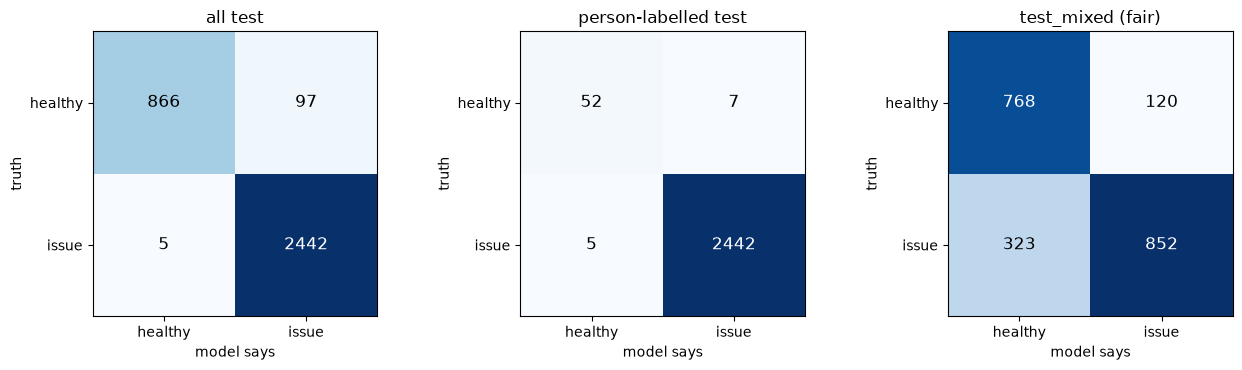

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
panels = [("all test", yt, test_df.pred.values), ("person-labelled test", yt[person], test_df.pred.values[person]),
          ("test_mixed (fair)", ym, mixed_df.pred.values)]
for ax, (name, y_true, y_pred) in zip(axes, panels):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["healthy", "issue"]); ax.set_yticks([0, 1], ["healthy", "issue"])
    ax.set_xlabel("model says"); ax.set_ylabel("truth"); ax.set_title(name)
plt.tight_layout(); plt.savefig(FIG_DIR / f"{EXPERIMENT}_confusion.png", dpi=120); plt.show()

## 10. Where does it go wrong? (fairness and error analysis)

- **By source dataset**: the photos come from different collections (different countries, cameras, lighting). A big gap
  between sources is a fairness and generalisation warning for the report. In `test` each source has only one class,
  so look at `test_mixed` for sources with both.
- **By condition**: of the test photos that have each condition, how many were flagged? This shows which conditions the
  model tends to miss (e.g. small caries).

In [15]:
rows = []
for (which, src), g in pd.concat([test_df.assign(set="test"), mixed_df.assign(set="test_mixed")]).groupby(["set", "dataset"]):
    s = scores(g.has_issue.values, g.p_issue.values, threshold)
    rows.append(dict(set=which, source=src, n=s["n"], n_issue=s["n_issue"], n_healthy=s["n_healthy"],
                     recall_issue=s["recall_issue"], recall_healthy=s["recall_healthy"]))
by_source = pd.DataFrame(rows).set_index(["set", "source"])
display(by_source.round(3))

by_condition = pd.DataFrame([
    dict(condition=c, n=int(test_df[c].sum()),
         flagged=float(test_df.loc[test_df[c] == 1, "pred"].mean()) if test_df[c].sum() else float("nan"))
    for c in CONDITIONS]).set_index("condition")
display(by_condition.round(3))

n  n_issue  n_healthy  recall_issue  \
set        source                                                       
test       dentalai              94        0         94           NaN   
           external_clean        14        0         14           NaN   
           kaggle_oral           59        0         59           NaN   
           mendeley_noncaries   472        0        472           NaN   
           roboflow_oral       2447     2447          0         0.998   
           zenodo               324        0        324           NaN   
test_mixed dentalai             370      242        128         0.897   
           external_clean        70       57         13         0.842   
           kaggle_oral          135      112         23         0.955   
           zenodo              1488      764        724         0.628   

                               recall_healthy  
set        source                              
test       dentalai                     0.787  
           external_clean               0.571  
           kaggle_oral                  0.881  
           mendeley_noncaries           0.936  
           roboflow_oral                  NaN  
           zenodo                       0.895  
test_mixed dentalai                     0.758  
           external_clean               0.615  
           kaggle_oral                  0.870  
           zenodo                       0.888

,n,flagged
condition,,
Calculus,415,1.000
Caries,811,1.000
Hypodontia,397,1.000
Mouth_Ulcer,568,1.000
Tooth_Discoloration,885,0.994


### Missed problems (false negatives) and false alarms

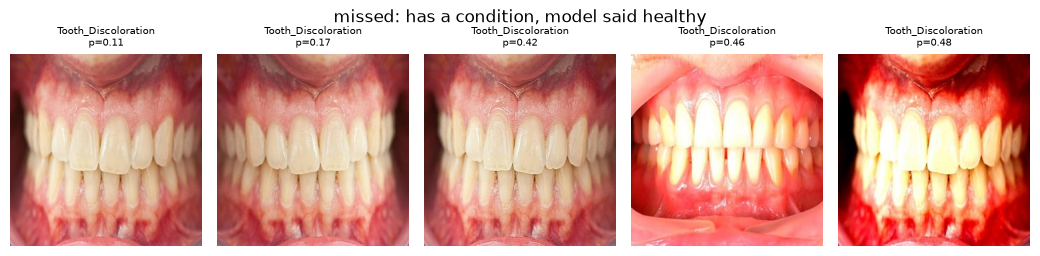

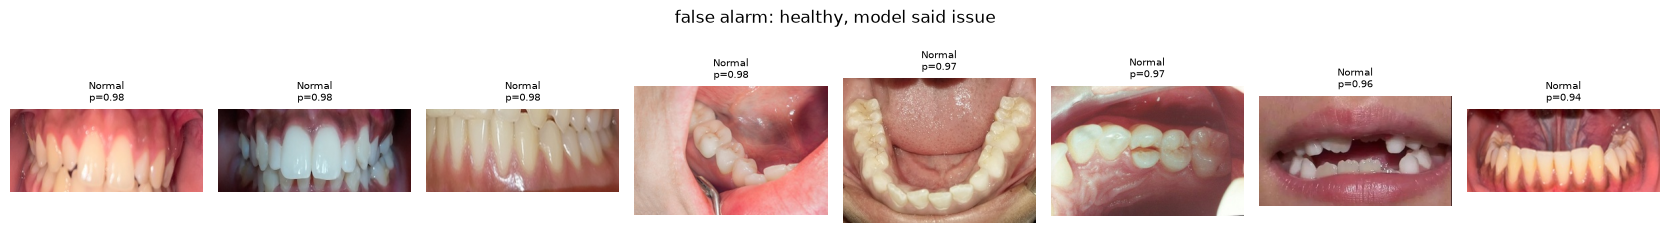

In [16]:
def show(frame, title, n=8):
    frame = frame.head(n)
    if frame.empty:
        print("none:", title); return
    fig, axes = plt.subplots(1, len(frame), figsize=(2.1 * len(frame), 2.6), squeeze=False)
    for ax, (_, r) in zip(axes[0], frame.iterrows()):
        with Image.open(r.cache) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{str(r['labels']).replace('|', chr(10))}\np={r.p_issue:.2f}", fontsize=7); ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()


show(test_df[(test_df.has_issue == 1) & (test_df.pred == 0)].sort_values("p_issue"), "missed: has a condition, model said healthy")
show(test_df[(test_df.has_issue == 0) & (test_df.pred == 1)].sort_values("p_issue", ascending=False), "false alarm: healthy, model said issue")

## 11. Robustness to poor photos

Patients take photos on phones in bad light. Each test photo is made blurry / dark / overexposed / low-resolution /
heavily compressed, and scored again. A big drop tells us which quality checks the app needs before screening.

In [17]:
rob_df = test_df.sample(min(len(test_df), 1500), random_state=SEED).reset_index(drop=True)
rob = []
for name in [None, *CORRUPTIONS]:
    lg, yr = predict_logits(model, loader(rob_df, eval_tf, corrupt=name))
    s = scores(yr, p_issue(lg, T), threshold)
    rob.append(dict(condition=name or "original", recall_issue=s["recall_issue"],
                    recall_healthy=s["recall_healthy"], balanced_accuracy=s["balanced_accuracy"]))
robustness = pd.DataFrame(rob).set_index("condition")
display(robustness.round(3))

,recall_issue,recall_healthy,balanced_accuracy
condition,,,
original,0.997,0.913,0.955
blur,0.967,0.816,0.891
dark (x0.5),0.994,0.918,0.956
bright (x1.6),1.000,0.828,0.914
low-res (1/3),0.975,0.811,0.893
JPEG q=20,0.987,0.705,0.846


## 12. Save the model and results

- `weights/Brandon/issue_classifier.pt`: weights plus everything needed to use them the same way (image size,
  normalisation, temperature, threshold). Gitignored; share it through the team drive.
- `results/Brandon/`: metrics JSON, training history and one row appended to `experiments.csv`, so the group can
  compare models on the same test set.

In [18]:
ckpt = {
    "task": "issue_or_not",
    "backbone": "efficientnet_b0",
    "head": "classifier.1",
    "classes": ["healthy", "issue"],
    "state_dict": best_state,
    "img_size": IMG_SIZE,
    "mean": MEAN, "std": STD,
    "temperature": T,
    "threshold": threshold,
    "unsure_below": UNSURE_BELOW,
    "config": {"cache_max_side": CACHE_SIDE, "epochs_run": int(hist.epoch.max()), "best_epoch": int(best_epoch),
               "batch": BATCH, "lr": LR, "seed": SEED, "dataset": "oral_dataset (Daniel, 2026-11-11)"},
    "notes": "Screening aid only, not a diagnosis. Stage 1 of 2: says whether any of the five conditions is likely; "
             "stage 2 (YOLO) locates and names them. Gum disease is not covered.",
}
weights_path = WEIGHTS_DIR / f"{'issue_classifier' + ('_smoke' if SMOKE else '')}.pt"
torch.save(ckpt, weights_path)

metrics = {"experiment": EXPERIMENT, "temperature": T, "threshold": threshold, "best_epoch": int(best_epoch),
           **{k: v for k, v in results.items()},
           "by_source": by_source.reset_index().to_dict("records"),
           "by_condition": by_condition.reset_index().to_dict("records"),
           "robustness": robustness.reset_index().to_dict("records")}
(OUT_DIR / f"{EXPERIMENT}_metrics.json").write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
hist.to_csv(OUT_DIR / f"{EXPERIMENT}_history.csv", index=False)

ta, tp_, tm = results["test_all"], results["test_person_only"], results["test_mixed"]
row = pd.DataFrame([dict(experiment=EXPERIMENT, date=time.strftime("%Y-%m-%d"), member="Brandon",
                         model="efficientnet_b0", task="issue_or_not", img_size=IMG_SIZE, epochs_run=int(hist.epoch.max()),
                         best_epoch=int(best_epoch), threshold=round(threshold, 4), temperature=round(T, 4),
                         mixed_recall_issue=tm["recall_issue"], mixed_recall_healthy=tm["recall_healthy"],
                         mixed_bal_acc=tm["balanced_accuracy"], mixed_auc=tm["roc_auc"],
                         test_recall_issue=ta["recall_issue"], test_recall_healthy=ta["recall_healthy"],
                         test_bal_acc=ta["balanced_accuracy"], test_auc=ta["roc_auc"],
                         person_recall_issue=tp_["recall_issue"], person_recall_healthy=tp_["recall_healthy"],
                         person_bal_acc=tp_["balanced_accuracy"], weights=str(weights_path.relative_to(REPO)))])
exp_csv = OUT_DIR / "experiments.csv"
row.to_csv(exp_csv, mode="a", header=not exp_csv.exists(), index=False)
print("saved", weights_path.relative_to(REPO), "and results in", OUT_DIR.relative_to(REPO))

saved models\classifier\weights\Brandon\issue_classifier.pt and results in models\classifier\results\Brandon


## 13. Use it on one photo

The same steps the backend will run: open → fix rotation → shrink like the cache → resize → normalise → model →
divide by `T` → probability → threshold / "not sure".

In [19]:
from PIL import ImageOps


def screen(path, ckpt=ckpt):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    im.thumbnail((ckpt["config"]["cache_max_side"],) * 2, Image.LANCZOS)
    x = eval_tf(im)[None].to(device)
    model.eval()
    with torch.no_grad():
        p = float((model(x).float() / ckpt["temperature"]).softmax(1)[0, 1])
    conf = max(p, 1 - p)
    verdict = ("not sure: see a dentist" if conf < ckpt["unsure_below"]
               else "possible issue" if p >= ckpt["threshold"] else "no issue seen")
    return {"p_issue": round(p, 3), "verdict": verdict}


r = test_df.sample(1, random_state=1).iloc[0]
print(r["labels"], "->", screen(r.src))

Mouth_Ulcer -> {'p_issue': 1.0, 'verdict': 'possible issue'}


## 14. Results at a glance, and what's next

Fill this in after the full run (copy from the tables above).

| | test_mixed (fair) | all test | person-labelled test |
|---|---|---|---|
| recall: issue | | | |
| recall: healthy | | | |
| balanced accuracy | | | |
| ROC-AUC | | | |

**Limitations to state in the report**
- In the shared val/test sets the source reveals the label (all problem photos are Roboflow). `test_mixed` avoids this;
  the val set used for early stopping and the threshold still has it.
- The photos are not from Singapore patients; sources differ in camera, lighting and population (see section 10).
- Some training labels come from Qwen, not people; the person-only test score shows how much that matters.
- Gum disease is not one of the classes, so "no issue seen" does not mean a healthy mouth.
- One photo can't show the whole mouth; the app should ask for several angles.

**Next:** stage 2, YOLO on the same dataset (`data.yaml`), to locate and name each condition on the photos this model flags.